In [1]:
import pandas as pd
import numpy as np
import re
import string

In [2]:
df = pd.read_csv("resume_data.csv")
df = df[['ID', 'Resume_str', 'Category']]
df.columns = ["ID", "Resume_Text", "Category"]
df.head()

,ID,Resume_Text,Category
0,16852973,HR ADMINISTRATOR/MARKETING ASSOCIATE\...,HR
1,22323967,"HR SPECIALIST, US HR OPERATIONS ...",HR
2,33176873,HR DIRECTOR Summary Over 2...,HR
3,27018550,HR SPECIALIST Summary Dedica...,HR
4,17812897,HR MANAGER Skill Highlights ...,HR


In [3]:
import re
import string

import nltk
from nltk.corpus import stopwords
nltk.download('stopwords')
stop_words = set(stopwords.words('english'))

def clean_text(text):
    text = text.lower()
    text = re.sub(r'\d+', '', text)
    text = text.translate(str.maketrans('', '', string.punctuation))
    words = text.split()
    words = [word for word in words if word not in stop_words]
    return " ".join(words)

df['cleaned_resume'] = df['Resume_Text'].apply(clean_text)
df.head()

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Admin\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


,ID,Resume_Text,Category,cleaned_resume
0,16852973,HR ADMINISTRATOR/MARKETING ASSOCIATE\...,HR,hr administratormarketing associate hr adminis...
1,22323967,"HR SPECIALIST, US HR OPERATIONS ...",HR,hr specialist us hr operations summary versati...
2,33176873,HR DIRECTOR Summary Over 2...,HR,hr director summary years experience recruitin...
3,27018550,HR SPECIALIST Summary Dedica...,HR,hr specialist summary dedicated driven dynamic...
4,17812897,HR MANAGER Skill Highlights ...,HR,hr manager skill highlights hr skills hr depar...


In [4]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
df.drop_duplicates(inplace=True)

tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1,3),
    min_df=10,
    max_df=0.20,
    sublinear_tf=True
)

X = tfidf.fit_transform(df['cleaned_resume'])
y = df['Category']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

from sklearn.svm import LinearSVC
model = LinearSVC(C=2.0)

model.fit(X_train, y_train)

from sklearn.metrics import accuracy_score
y_pred = model.predict(X_test)

print("Improved Accuracy:", accuracy_score(y_test, y_pred))


Improved Accuracy: 0.7525150905432596


In [5]:
def predict_resume(text):
    text = clean_text(text)
    vector = tfidf.transform([text])
    return model.predict(vector)

In [6]:
print(predict_resume("""
Experienced Data Scientist with strong background in Python,
machine learning, deep learning, data analysis, pandas, numpy,
SQL, data visualization, and predictive modeling.
"""))

['BANKING']


In [7]:
print("=== Resume Screening System ===")
sample = "Python machine learning data analysis SQL"
print("Input Resume:", sample)
result = predict_resume(sample)
print("Predicted Category:", result)

=== Resume Screening System ===
Input Resume: Python machine learning data analysis SQL
Predicted Category: ['ENGINEERING']


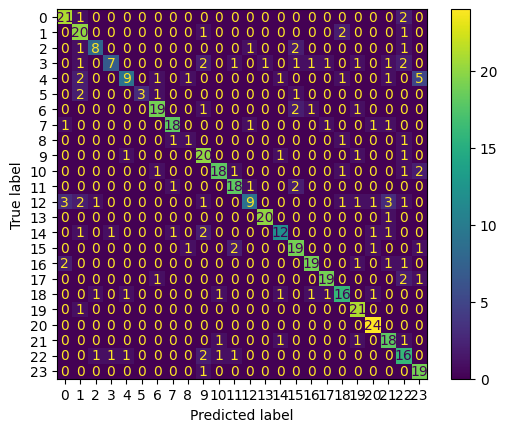

In [8]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)

disp.plot()
plt.show()
